In [139]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table


file_dir = "C:/Astrostuff/PhD/Data/"
# file_name = "star_detections_vs_fwhm.csv"
file_name = "star_detections.csv"
data = Table.read(file_dir+file_name, format = "csv", converters = {"object_id":str})
print(len(data))
print(data)

5586
fwhm kernel_std detections       source     
---- ---------- ---------- -----------------
 1.0        1.0          2 39627770304661746
 5.0        1.0          4 39627770304661746
 9.0        1.0          5 39627770304661746
13.0        1.0          3 39627770304661746
17.0        1.0          0 39627770304661746
21.0        1.0          0 39627770304661746
25.0        1.0          1 39627770304661746
29.0        1.0          0 39627770304661746
33.0        1.0          0 39627770304661746
37.0        1.0          0 39627770304661746
 ...        ...        ...               ...
17.0        3.0          0 39633422527758917
21.0        3.0         20 39633422527758917
25.0        3.0         23 39633422527758917
29.0        3.0         23 39633422527758917
33.0        3.0         22 39633422527758917
37.0        3.0         22 39633422527758917
41.0        3.0         17 39633422527758917
45.0        3.0         14 39633422527758917
49.0        3.0         16 39633422527758917
53.0 

In [140]:
# print(data[8736])
# data = data[8736:]

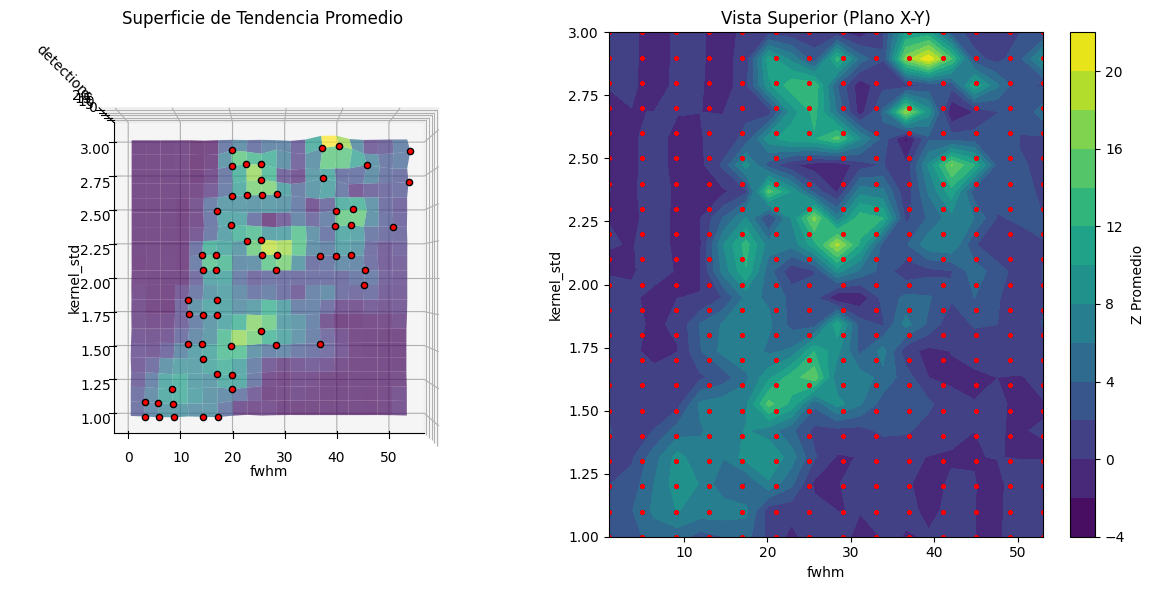

In [141]:
from scipy.stats import binned_statistic_2d
from scipy.interpolate import griddata
from scipy.ndimage import maximum_filter

x = data['fwhm']
y = data['kernel_std']
z = data['detections']


grid_size = 20
xi = np.linspace(x.min(), x.max(), grid_size)
yi = np.linspace(y.min(), y.max(), grid_size)
X, Y = np.meshgrid(xi, yi)

# Interpolación cúbica para obtener los valores Z promedio en la rejilla
Z_grid = griddata((x, y), z, (X, Y), method='cubic')

Z_grid_filled = np.nan_to_num(Z_grid, nan=np.nanmin(Z_grid))

size_ventana = 2
filtro_max = maximum_filter(Z_grid_filled, size=size_ventana)
es_maximo_local = (Z_grid_filled == filtro_max) & (Z_grid_filled > np.nanmean(Z_grid_filled))
indices_y, indices_x = np.where(es_maximo_local)

max_x = X[indices_y, indices_x]
max_y = Y[indices_y, indices_x]
max_z = Z_grid[indices_y, indices_x]

# 3. Graficar
fig = plt.figure(figsize=(12, 6))

# Gráfico 3D con los puntos originales y la superficie promedio
ax = fig.add_subplot(121, projection='3d')
# ax.scatter(x, y, z, c='red', alpha=0.5, s=15, label='Datos reales')
ax.plot_surface(X, Y, Z_grid, cmap='viridis', alpha=0.7, edgecolor='none')
ax.scatter(max_x, max_y, max_z, color='red', s=20, depthshade=False, edgecolor='black', linewidth=1, label='Máximos Locales')
ax.set_title('Superficie de Tendencia Promedio')
ax.set_xlabel('fwhm')
ax.set_ylabel('kernel_std')
ax.set_zlabel('detections')


# max_x = []
# max_y = []
# max_z = []
#
# for i in range(grid_size):
#     # Extraer la columna i (fijando X, variando Y)
#     z_columna = Z_grid[:, i]
#
#     # Ignorar si hay valores NaN debido a los bordes de la interpolación
#     if not np.isnan(z_columna).all():
#         idx_max_y = np.nanargmax(z_columna) # Índice del máximo Z en esa columna
#
#         # Guardar las coordenadas exactas de la rejilla
#         max_x.append(X[idx_max_y, i])
#         max_y.append(Y[idx_max_y, i])
#         max_z.append(Z_grid[idx_max_y, i])
#
# ax.scatter(max_x, max_y, max_z, color='red', linewidth=4, zorder=10, label='Máximos de la Superficie')

# Mapa de calor 2D del promedio de Z
ax2 = fig.add_subplot(122)
contour = ax2.contourf(X, Y, Z_grid, cmap='viridis', levels=15)
fig.colorbar(contour, ax=ax2, label='Z Promedio')
ax2.scatter(x, y, c='red', alpha=0.3, s=5)
ax2.set_title('Vista Superior (Plano X-Y)')
ax2.set_xlabel('fwhm')
ax2.set_ylabel('kernel_std')

# ax.view_init(elev=25, azim=30)
ax.view_init(elev=90, azim=-90)

plt.tight_layout()
plt.show()

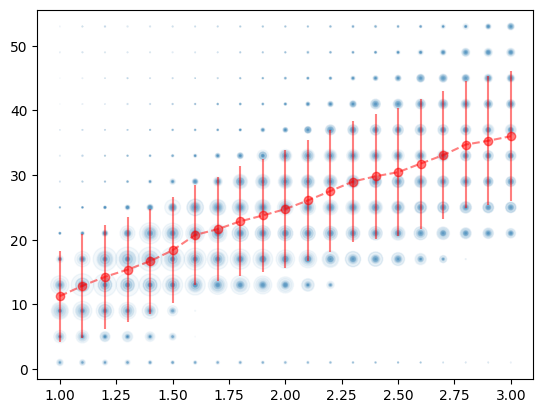

In [177]:
# print(np.unique(y))
av_w_x = []
av_w_x_std = []
av_w_y = np.unique(y)
for kern in av_w_y:
    # print(kern)
    sel_x = x[y==kern]
    sel_z = z[y==kern]
    wx = np.average(sel_x,weights=sel_z)
    w_var = np.average((sel_x - wx)**2, weights=sel_z)
    wx_std = np.sqrt(w_var)
    av_w_x.append(wx)
    av_w_x_std.append(wx_std)
# print(av_w_y)
# print(av_w_x)
# print(len(av_w_y))
# print(len(av_w_x))
# plt.scatter(x,y, s = z**2/10, alpha = 0.05)
# plt.scatter(x,y, s = 1, alpha = 0.05)
# plt.scatter(av_w_x,av_w_y, alpha = 1)
plt.scatter(y,x, s = z**2/10, alpha = 0.05)
# plt.scatter(av_w_y,av_w_x, alpha = 1)
plt.errorbar(av_w_y,av_w_x,av_w_x_std,0, alpha = 0.5, fmt = "o--", color = "red", facecolor=None)
plt.show()

In [131]:
img = np.zeros((50,50))
print(img)
x,y = img.shape
print(x, y)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
50 50


Ecuación de la recta: y = 12.45*X + -0.31
y = kernel, x = std
Coeficiente R²: 0.9945
[(0, 8.6), (4, 22.6)]
[(0, np.float64(-0.3053376199453659)), (4, np.float64(49.47720021425705))]


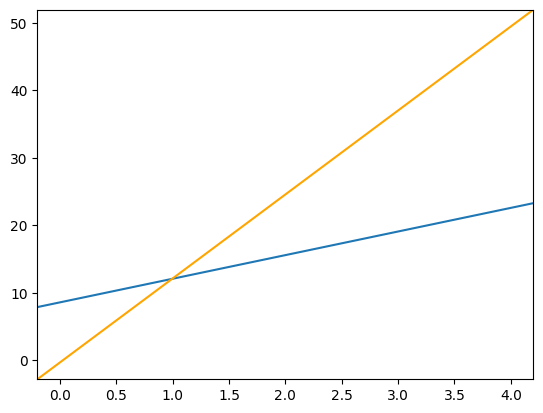

In [165]:
from sklearn.linear_model import LinearRegression

# X = [[lil_x] for lil_x in av_w_x]
# Y = av_w_y
X = [[lil_x] for lil_x in av_w_y]
Y = av_w_x

modelo = LinearRegression()
modelo.fit(X, Y)

pendiente = modelo.coef_[0]
interseccion = modelo.intercept_

# main_fwhm = 8.6 + 3.5 * this_std

print(f"Ecuación de la recta: y = {pendiente:.2f}*X + {interseccion:.2f}")
print("y = kernel, x = std")
r2 = modelo.score(X, Y)
print(f"Coeficiente R²: {r2:.4f}")

pts_mod1=[]
pts_mod2=[]
for x_std in [0,4]:
    y_mod1 = 8.6 + 3.5 * x_std
    y_mod2 = modelo.predict(np.array([[x_std]]))[0]
    pts_mod1.append((x_std,y_mod1))
    pts_mod2.append((x_std,y_mod2))

print(pts_mod1)
print(pts_mod2)

plt.axline(pts_mod1[0],pts_mod1[1])
plt.axline(pts_mod2[0],pts_mod2[1], color = "orange")
plt.show()